# Kaggle · YOLO11m trên VisDrone MOT/DET

**Nguồn:** `tiendq/visdrone-mot-det-converted` · **Cấu hình gốc:** [`ntrThanh/uav-tracking` @ `950379c`](https://github.com/ntrThanh/uav-tracking/tree/950379c83ce853c8dce1d0110907a0753cc6f007).

Cấu hình: `imgsz=640, epochs=80, batch=16, optimizer=SGD, lr0=.01, cos_lr=True, close_mosaic=10, patience=20, seed=0`.

**Đầu ra:** checkpoint (`best.pt`, `last.pt`), cấu hình và thông tin môi trường, `results.csv`, một ảnh đường cong loss/mAP theo epoch, đánh giá validation, confusion matrix, **3 ảnh crop phóng to** minh họa FN vật nhỏ / FP / nhầm lớp (khi tìm được trường hợp thỏa tiêu chí), báo cáo JSON, và **một ZIP kết quả**.

> Kaggle: Add Input `tiendq/visdrone-mot-det-converted`, bật **GPU** và **Internet** (để cài Ultralytics và tải pretrained `yolo11m.pt`). `test-dev` **không** được dùng để chọn model, vẽ ca lỗi hay điều chỉnh cấu hình.

In [ ]:
from pathlib import Path
import os, sys, json, time, shutil, subprocess, csv, platform, random, math
from datetime import datetime, timezone

# CẤU HÌNH 
DATASET_ROOT = Path('/kaggle/input/datasets/tiendq/visdrone-mot-det-converted/uav_tracking_mot_det')
VARIANT = 'det'           # 'mot', 'det', hoặc 'motdet'
MODEL_NAME = 'yolo11m.pt'
IMGSZ = 640
EPOCHS = 80              # đổi thành 2 để chạy smoke-test trước
BATCH = 16              
DEVICE = 0               # một GPU;
WORKERS = 4
SEED = 0
PATIENCE = 20
SAVE_PERIOD = 10          # checkpoint giữa quá trình (chỉ best/last vào ZIP)

# Định tính: minh họa các ca lỗi trên VAL, không phải mAP chính thức
ERROR_SCAN_LIMIT = 700   # số ảnh validation tối đa sẽ duyệt
ERROR_BATCH = 4
ERROR_CONF = 0.25         # ngưỡng xác định lỗi minh họa
ERROR_IOU = 0.50         # ngưỡng IoU ghép GT và prediction

REPO_URL = 'https://github.com/ntrThanh/uav-tracking'
REPO_SHA = '950379c83ce853c8dce1d0110907a0753cc6f007'
WORK = Path('/kaggle/working')
SUFFIX = '' if VARIANT == 'mot' else f'_{VARIANT}'
YOLO_DIRNAME = f'yolo{SUFFIX}'
COCO_DIRNAME = f'coco{SUFFIX}'
RUN_NAME = f'T1_yolo11m_640_{VARIANT}'
RUNS_ROOT = WORK / 'yolo11_runs'
RUN_DIR = RUNS_ROOT / RUN_NAME
STAGE_ROOT = WORK / f'visdrone_yolo_{VARIANT}'
PACKAGE = WORK / f'{RUN_NAME}_artifacts.zip'

assert VARIANT in ('mot','det','motdet')
WORK.mkdir(parents=True, exist_ok=True)
print('Variant:', VARIANT, '| Run:', RUN_NAME)
print('Dataset root:', DATASET_ROOT)

Variant: det | Run: T1_yolo11m_640_det
Dataset root: /kaggle/input/datasets/tiendq/visdrone-mot-det-converted/uav_tracking_mot_det


## 1. Cài đặt và kiểm tra GPU

Giữ checkpoint và các file kết quả trên `/kaggle/working/`. Phiên bản thư viện thực tế được lưu vào `env.txt` để tái lập thí nghiệm.

In [2]:
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'ultralytics>=8.3,<9', 'pyyaml'], check=True)
import torch, ultralytics, yaml, pandas as pd, numpy as np
from PIL import Image, ImageDraw, ImageFont
import matplotlib.pyplot as plt

if not torch.cuda.is_available():
    raise RuntimeError('Chưa có GPU CUDA: Kaggle Notebook → Settings → Accelerator → GPU.')
if DEVICE >= torch.cuda.device_count():
    raise ValueError(f'DEVICE={DEVICE} nhưng chỉ có {torch.cuda.device_count()} GPU')
print('torch:', torch.__version__)
print('ultralytics:', ultralytics.__version__)
print('GPU:', torch.cuda.get_device_name(DEVICE))
print('Free working disk (GiB):', round(shutil.disk_usage(WORK).free/1024**3, 2))

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
torch: 2.11.0+cu128
ultralytics: 8.4.197
GPU: Tesla T4
Free working disk (GiB): 19.5


## 2. Chuẩn bị data theo layout YOLO mà **không copy lại ảnh**

Dataset Kaggle đã có `data/raw/` + `data/processed/`, nhưng ảnh trong YOLO của repo vốn là **symlink**. Ta đọc `links_manifest.json` rồi tạo lại symlink **trong thư mục làm việc**. Nhãn TXT cũng được link tới dataset đã mount; **không sửa `/kaggle/input`**.

> Nếu Kaggle mount dữ liệu dưới đường dẫn hơi khác, cell này sẽ thử dò thư mục `uav_tracking_mot_det` trước khi báo lỗi. Nếu chỉ thấy ZIP mà chưa giải nén, cần giải nén ZIP vào `/kaggle/working` và trỏ `DATASET_ROOT` đến thư mục đó.

In [3]:
def find_bundle_root(configured: Path) -> Path:
    if (configured/'data'/'processed').is_dir():
        return configured
    options = list(Path('/kaggle/input').glob('*/uav_tracking_mot_det'))
    options += list(Path('/kaggle/input').glob('*/data'))
    for p in options:
        candidate = p.parent if p.name == 'data' else p
        if (candidate/'data'/'processed'/YOLO_DIRNAME).is_dir():
            print('Tự tìm được DATASET_ROOT:', candidate)
            return candidate
    raise FileNotFoundError(
        f'Không tìm thấy thư mục data/processed trong {configured}. '
        'Kiểm tra Kaggle Add Input và DATASET_ROOT. '
        'Notebook này dùng dataset đã giải nén thành thư mục, không phải ZIP chưa giải nén.'
    )

DATASET_ROOT = find_bundle_root(DATASET_ROOT)
SOURCE_YOLO = DATASET_ROOT/'data'/'processed'/YOLO_DIRNAME
assert SOURCE_YOLO.is_dir(), f'Thiếu {SOURCE_YOLO}'
assert (DATASET_ROOT/'data'/'raw').is_dir(), 'Thiếu data/raw/ chứa ảnh thật'
MANIFEST = DATASET_ROOT/'links_manifest.json'

# Lấy mapping từ đường dẫn ảnh YOLO sang ảnh gốc. Chỉ đọc manifest của variant đã chọn.
image_map = {}
if MANIFEST.exists():
    manifest = json.loads(MANIFEST.read_text(encoding='utf-8'))
    prefix = f'data/processed/{YOLO_DIRNAME}/'
    for item in manifest['links']:
        link = str(item['link'])
        if not link.startswith(prefix) or '/images/' not in link or item.get('is_dir', False):
            continue
        # e.g. data/processed/yolo/train/images/foo.jpg
        parts = Path(link).parts
        if len(parts) < 6:
            continue
        split, name = parts[3], parts[-1]
        image_map[(split, name)] = DATASET_ROOT / item['target']
    print(f'Đọc {len(image_map):,} symlink ảnh từ {MANIFEST.name}')
else:
    print('Không có links_manifest.json: sẽ thử dùng ảnh YOLO có sẵn hoặc dựng lại từ COCO JSON.')

# Fallback: COCO images[].file_name trỏ đến ảnh gốc, ánh xạ tên ảnh phẳng do prepare.py sinh ra.
def map_images_from_coco(split: str) -> dict:
    ann_file = DATASET_ROOT/'data'/'processed'/COCO_DIRNAME/f'{split}.json'
    if not ann_file.is_file():
        raise FileNotFoundError(f'Không có manifest và COCO fallback: {ann_file}')
    ann = json.loads(ann_file.read_text(encoding='utf-8'))
    out = {}
    for im in ann['images']:
        src = im['file_name']
        if im.get('source') == 'det':
            name = 'det_' + Path(src).name
        else:
            name = f"{im['seq']}_{int(im['frame']):07d}.jpg"
        out[(split,name)] = DATASET_ROOT/'data'/'raw'/src
    return out

# Xóa duy nhất staging của lần chạy trước. Không đụng dữ liệu Kaggle Input.
if STAGE_ROOT.exists():
    shutil.rmtree(STAGE_ROOT)

n_images = {}
for split in ('train', 'val', 'test-dev'):
    source_labels = SOURCE_YOLO/split/'labels'
    assert source_labels.is_dir(), f'Thiếu nhãn: {source_labels}'
    label_files = sorted(source_labels.glob('*.txt'))
    assert label_files, f'{split}: không có nhãn TXT'

    staged_images = STAGE_ROOT/split/'images'
    staged_labels = STAGE_ROOT/split/'labels'
    staged_images.mkdir(parents=True, exist_ok=True)
    staged_labels.mkdir(parents=True, exist_ok=True)

    if not MANIFEST.exists():
        image_map.update(map_images_from_coco(split))

    missing = []
    for f in label_files:
        image_name = f.with_suffix('.jpg').name
        raw_file = image_map.get((split, image_name))
        if raw_file is None:
            source_image = SOURCE_YOLO/split/'images'/image_name
            raw_file = source_image if source_image.is_file() else None
        if raw_file is None or not raw_file.is_file():
            missing.append(image_name)
            continue
        (staged_images/image_name).symlink_to(raw_file)
        (staged_labels/f.name).symlink_to(f)
    if missing:
        raise FileNotFoundError(f'{split}: thiếu {len(missing)} ảnh gốc. Ví dụ: {missing[:4]}')
    n_images[split] = len(label_files)
    print(f'{split:8s}: {len(label_files):6,d} images + labels (symlinks)')

# Dùng chính names/10 class từ visdrone.yaml của repo, chỉ sửa path sang Kaggle working.
src_yaml = SOURCE_YOLO/'visdrone.yaml'
assert src_yaml.exists(), f'Thiếu {src_yaml}'
yolo_cfg = yaml.safe_load(src_yaml.read_text(encoding='utf-8'))
yolo_cfg['path'] = str(STAGE_ROOT)
yolo_cfg.update(train='train/images', val='val/images', test='test-dev/images')
DATA_YAML = STAGE_ROOT/'visdrone.yaml'
DATA_YAML.write_text(yaml.safe_dump(yolo_cfg, allow_unicode=True, sort_keys=False), encoding='utf-8')
assert len(yolo_cfg['names']) == 10, 'Dự kiến dataset 10 lớp VisDrone'
print('\nTraining YAML:', DATA_YAML)
print(DATA_YAML.read_text(encoding='utf-8')[:700])

Đọc 8,572 symlink ảnh từ links_manifest.json
train   :  6,414 images + labels (symlinks)
val     :    548 images + labels (symlinks)
test-dev:  1,610 images + labels (symlinks)

Training YAML: /kaggle/working/visdrone_yolo_det/visdrone.yaml
path: /kaggle/working/visdrone_yolo_det
train: train/images
val: val/images
test: test-dev/images
names:
  0: pedestrian
  1: people
  2: bicycle
  3: car
  4: van
  5: truck
  6: tricycle
  7: awning-tricycle
  8: bus
  9: motor



## 3. Fine-tune YOLO11m

`max_det=1000` để không cắt mất detections trên cảnh đông.

In [4]:
from ultralytics import YOLO

train_config = dict(
    model=MODEL_NAME, data=str(DATA_YAML), variant=VARIANT,
    imgsz=IMGSZ, epochs=EPOCHS, batch=BATCH, optimizer='SGD',
    lr0=0.01, cos_lr=True, close_mosaic=10, patience=PATIENCE,
    seed=SEED, device=DEVICE, workers=WORKERS, amp=True,
    max_det=1000, save=True, save_period=SAVE_PERIOD,
    cache=False, pretrained=True,
    project=str(RUNS_ROOT), name=RUN_NAME,
    repo=REPO_URL, repo_commit=REPO_SHA, dataset_root=str(DATASET_ROOT),
)
RUN_DIR.mkdir(parents=True, exist_ok=True)
(RUN_DIR/'run_config.yaml').write_text(yaml.safe_dump(train_config, allow_unicode=True, sort_keys=False))

model = YOLO(MODEL_NAME)
started_at = time.time()
train_results = model.train(
    data=str(DATA_YAML), imgsz=IMGSZ, epochs=EPOCHS, batch=BATCH,
    optimizer='SGD', lr0=0.01, cos_lr=True,
    close_mosaic=10, patience=PATIENCE, seed=SEED,
    device=DEVICE, workers=WORKERS, amp=True, cache=False,
    max_det=1000, save=True, save_period=SAVE_PERIOD,
    project=str(RUNS_ROOT), name=RUN_NAME, exist_ok=True,
)
duration_hours = (time.time()-started_at)/3600
BEST_PT = RUN_DIR/'weights'/'best.pt'
LAST_PT = RUN_DIR/'weights'/'last.pt'
assert BEST_PT.is_file(), f'Không thấy checkpoint tốt nhất: {BEST_PT}'
assert LAST_PT.is_file(), f'Không thấy last.pt: {LAST_PT}'
print('Training complete:', RUN_DIR)
print('Duration hours:', round(duration_hours,3))
print('Best checkpoint:', BEST_PT, 'size MB:', round(BEST_PT.stat().st_size/1e6,1))

Ultralytics 8.4.197 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/kaggle/working/visdrone_yolo_det/visdrone.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=80, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=1000, mixup=0.0, mode=train, model=yolo11m.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=T1_yolo11m_640_det, nbs=64, nms=None, opse

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


       2/80      9.35G       1.56      1.156     0.9026        938        640: 100% ━━━━━━━━━━━━ 401/401 2.5it/s 2:42
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 18/18 2.7it/s 6.5s
                   all        548      38759      0.433      0.314      0.302      0.169

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/80      9.75G      1.625      1.192     0.9119       1693        640: 100% ━━━━━━━━━━━━ 401/401 2.5it/s 2:42
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 18/18 2.7it/s 6.6s
                   all        548      38759      0.392      0.308      0.279      0.154

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       4/80      9.18G      1.637      1.197     0.9165        746        640: 100% ━━━━━━━━━━━━ 401/401 2.5it/s 2:42
                 Class     Images  Instances      Box(P 

## 4. **Một hình** đường cong train/val loss + mAP50–95 theo epoch

YOLO11 detection có 3 thành phần loss: `box`, `cls`, `dfl`. Để đáp ứng yêu cầu “mỗi mô hình một hình”, tạo **1 PNG gồm 4 ô**: 3 ô loss train-vs-val và 1 ô mAP50/mAP50-95. Đồng thời giữ nguyên `results.csv` và `results.png` do Ultralytics xuất.

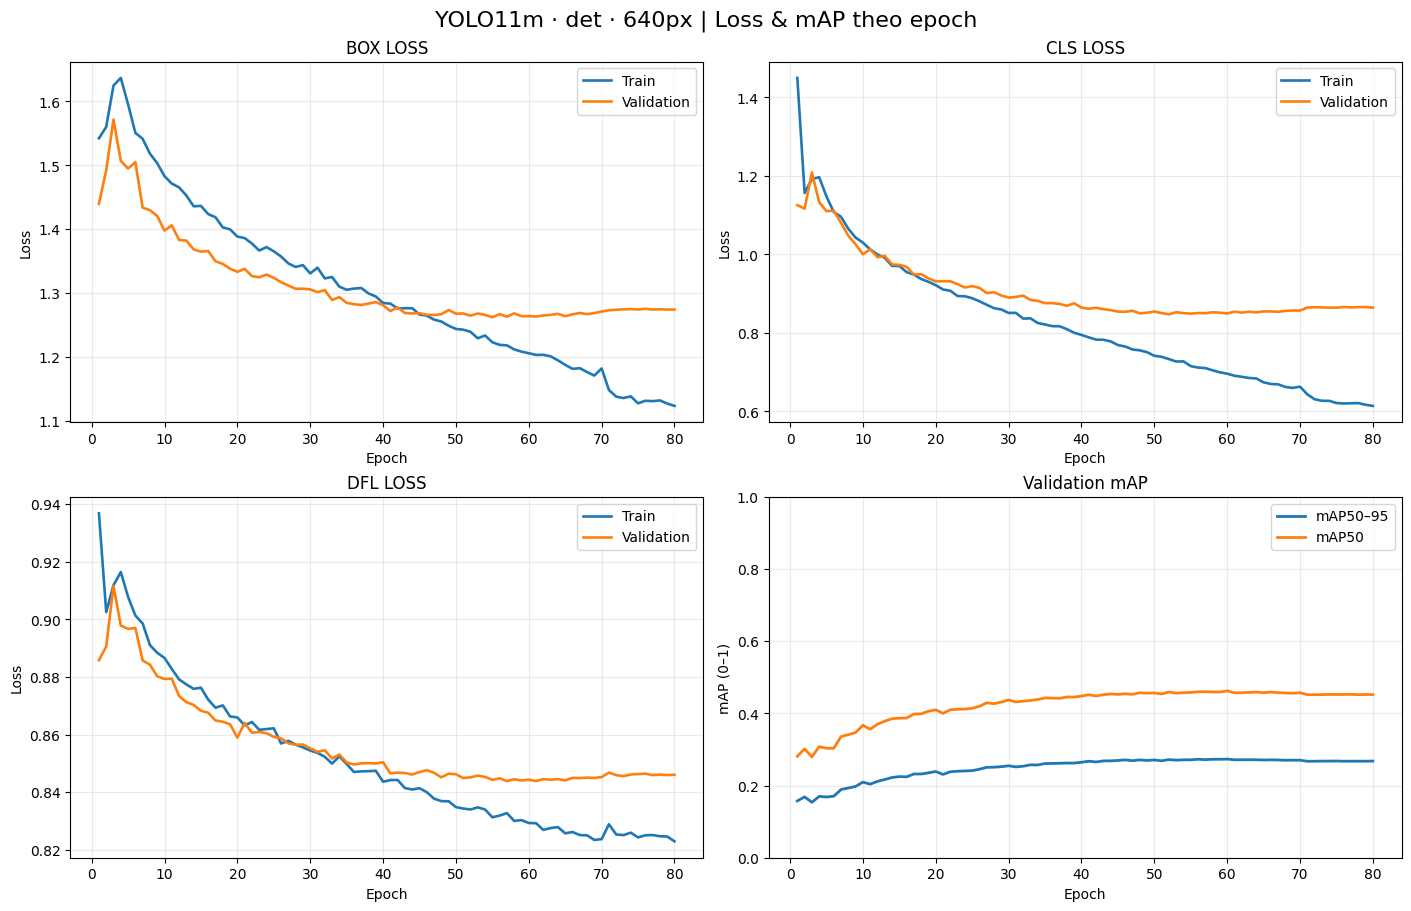

Best epoch: 60 Best val mAP50-95: 0.27337
Saved: /kaggle/working/yolo11_runs/T1_yolo11m_640_det/training_curves_loss_map.png


In [5]:
results_csv = RUN_DIR/'results.csv'
assert results_csv.is_file(), f'Thiếu {results_csv}'
df = pd.read_csv(results_csv)
df.columns = df.columns.str.strip()
assert 'epoch' in df.columns

fig, axes = plt.subplots(2,2, figsize=(14,9), constrained_layout=True)
for ax, metric in zip(axes.flat[:3], ('box_loss','cls_loss','dfl_loss')):
    for prefix, label in [('train','Train'), ('val','Validation')]:
        key = f'{prefix}/{metric}'
        if key in df.columns:
            ax.plot(df['epoch'],df[key],linewidth=1.9,label=label)
    ax.set_title(metric.replace('_',' ').upper()); ax.set_xlabel('Epoch')
    ax.set_ylabel('Loss'); ax.grid(alpha=0.25); ax.legend()
ax=axes.flat[3]
for key,label in [('metrics/mAP50-95(B)','mAP50–95'),('metrics/mAP50(B)','mAP50')]:
    if key in df.columns:
        ax.plot(df['epoch'],df[key],linewidth=2,label=label)
ax.set_title('Validation mAP'); ax.set_xlabel('Epoch');ax.set_ylabel('mAP (0–1)')
ax.set_ylim(0,1); ax.grid(alpha=0.25); ax.legend()
fig.suptitle(f'YOLO11m · {VARIANT} · {IMGSZ}px | Loss & mAP theo epoch',fontsize=16)
CURVES = RUN_DIR/'training_curves_loss_map.png'
fig.savefig(CURVES,dpi=170,bbox_inches='tight')
plt.show();plt.close(fig)

best_epoch = None
best_map = None
map_key = 'metrics/mAP50-95(B)'
if map_key in df and df[map_key].notna().any():
    idx = df[map_key].idxmax()
    best_epoch = int(df.loc[idx, 'epoch'])
    best_map = float(df.loc[idx, map_key])
print('Best epoch:',best_epoch,'Best val mAP50-95:',best_map)
print('Saved:',CURVES)

## 5. Đánh giá checkpoint tốt nhất trên **validation**

Tính lại mAP trên `val`, lưu JSON tổng hợp, kết quả per-class, confusion matrix. Mục này không sử dụng `test-dev` để tránh làm lệch đánh giá cuối.

In [6]:
best_model = YOLO(str(BEST_PT))
metrics = best_model.val(
    data=str(DATA_YAML), split='val', imgsz=IMGSZ,
    batch=min(BATCH,8), device=DEVICE, workers=WORKERS,
    conf=0.001, iou=0.7, max_det=1000, plots=True,
    project=str(RUNS_ROOT), name=RUN_NAME+'_val_best', exist_ok=True,
)
VALIDATION_DIR = RUNS_ROOT / (RUN_NAME+'_val_best')
validation_summary = {
    'dataset_variant': VARIANT, 'split':'val',
    'mAP50_95': float(metrics.box.map),
    'mAP50': float(metrics.box.map50),
    'mAP75': float(metrics.box.map75),
    'precision_mean': float(metrics.box.mp),
    'recall_mean': float(metrics.box.mr),
    'best_epoch_from_train_csv': best_epoch,
    'best_map_train_csv': best_map,
    'n_train_images': n_images['train'],
    'n_val_images': n_images['val'],
    'n_test_dev_images': n_images['test-dev'],
}
(RUN_DIR/'validation_metrics.json').write_text(json.dumps(validation_summary,indent=2,ensure_ascii=False))
class_names={int(k):str(v) for k,v in yolo_cfg['names'].items()}
per_class=[]
try:
    for idx, ap in enumerate(metrics.box.maps):
        per_class.append({'class_id':idx,'class':class_names.get(idx,str(idx)), 'AP50_95':float(ap)})
except Exception as e:
    print('Không trích được AP per-class:',e)
pd.DataFrame(per_class).to_csv(RUN_DIR/'per_class_ap.csv',index=False)
print(json.dumps(validation_summary, indent=2,ensure_ascii=False))
print('Validation plots:',VALIDATION_DIR)

Ultralytics 8.4.197 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO11m summary (fused): 125 layers, 20,037,742 parameters, 0 gradients, 67.8 GFLOPs
val: Fast image access ✅ (ping: 0.4±0.1 ms, read: 224.3±50.2 MB/s, size: 153.1 KB)
val: Scanning /kaggle/working/visdrone_yolo_det/val/labels.cache... 548 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 548/548 164.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 69/69 5.1it/s 13.6s
                   all        548      38759      0.578      0.454      0.463      0.275
            pedestrian        520       8844      0.628      0.482      0.517      0.241
                people        482       5125      0.628      0.364      0.388       0.15
               bicycle        364       1287      0.355      0.225      0.204     0.0911
                   car        515      14064      0.778      0.821       0.83      0.584
                   van     

## 6. Chọn 3 ca lỗi thực tế từ validation (FN, FP, nhầm lớp)

- **FN vật nhỏ:** GT có diện tích `<32×32 px` (có ít nhất một cạnh ≥8px), không có prediction khớp bất kỳ lớp nào ở IoU≥0.50 tại ngưỡng confidence 0.25.
- **FP:** detection score≥0.35, không trùng GT bất kỳ lớp nào (IoU `<0.10`) và không nằm phần lớn trong vùng `ignored`, nếu metadata ignored khả dụng.
- **Nhầm lớp:** prediction trùng GT (IoU≥0.50), nhưng dự đoán sai giữa `car↔van` hoặc `pedestrian↔people`, đồng thời không có detection đúng lớp ở IoU≥0.50.

Mỗi ảnh crop gồm **hai panel cùng một vùng phóng to**: `GROUND TRUTH` (trái) và `PREDICTION` (phải); kèm file JSON về tọa độ và confidence. Chỉ tạo ảnh nếu **phát hiện trường hợp thật**. Nếu không có một loại lỗi trong số ảnh đã duyệt, ghi `not_found` chứ không bịa ví dụ. Tiêu chí này để minh họa, **không thay thế đánh giá AP chính thức**.

In [7]:
def xyxy_iou(a, b):
    ax1,ay1,ax2,ay2=map(float,a)
    bx1,by1,bx2,by2=map(float,b)
    w=max(0,min(ax2,bx2)-max(ax1,bx1))
    h=max(0,min(ay2,by2)-max(ay1,by1))
    inter=w*h
    area_a=max(0,ax2-ax1)*max(0,ay2-ay1)
    area_b=max(0,bx2-bx1)*max(0,by2-by1)
    return inter/(area_a+area_b-inter+1e-9)

def intersection_over_prediction(pred, ignored_xyxy):
    x1,y1,x2,y2 = pred
    a=max(0,(x2-x1))*max(0,(y2-y1))
    ix=max(0,min(x2,ignored_xyxy[2])-max(x1,ignored_xyxy[0]))
    iy=max(0,min(y2,ignored_xyxy[3])-max(y1,ignored_xyxy[1]))
    return (ix*iy)/(a+1e-9)

def read_gt(label_file, w,h):
    gt=[]
    for line in label_file.read_text().splitlines():
        cols=line.strip().split()
        if len(cols)<5:continue
        c=int(cols[0]);cx,cy,bw,bh=map(float,cols[1:5])
        x1,y1,x2,y2=(cx-bw/2)*w,(cy-bh/2)*h,(cx+bw/2)*w,(cy+bh/2)*h
        gt.append({'cls':c,'box':[x1,y1,x2,y2]})
    return gt

def get_predictions(result):
    if result.boxes is None or len(result.boxes)==0:
        return []
    coords=result.boxes.xyxy.cpu().numpy()
    cls=result.boxes.cls.cpu().numpy()
    conf=result.boxes.conf.cpu().numpy()
    return [dict(cls=int(c),conf=float(s),box=b.tolist()) for b,c,s in zip(coords,cls,conf)]

# ignored regions trong COCO JSON do prepare.py sinh; bỏ qua FP rơi vào ignored.
ignored_by_image = {}
val_json = DATASET_ROOT/'data'/'processed'/COCO_DIRNAME/'val.json'
if val_json.exists():
    try:
        obj=json.loads(val_json.read_text(encoding='utf-8'))
        ids_to_names={}
        for im in obj['images']:
            if im.get('source') == 'det':
                key='det_'+Path(im['file_name']).name
            else:
                key=f"{im['seq']}_{int(im['frame']):07d}.jpg"
            ids_to_names[im['id']]=key
        for record in obj.get('ignored_regions',[]):
            key=ids_to_names.get(record['image_id'])
            if key is None:continue
            x,y,w,h=record['bbox']
            ignored_by_image.setdefault(key,[]).append([x,y,x+w,y+h])
        print('Loaded ignored regions for',len(ignored_by_image),'validation images')
    except Exception as exc:
        print('Không đọc được ignored regions; FP cần kiểm tra thủ công:',exc)
else:
    print('Không có COCO val ignored regions; FP cần kiểm tra thủ công.')

ERRORS_DIR = RUN_DIR/'errors'
ERRORS_DIR.mkdir(parents=True,exist_ok=True)
validation_images=sorted((STAGE_ROOT/'val'/'images').glob('*.jpg'))
random.Random(SEED).shuffle(validation_images)
validation_images=validation_images[:ERROR_SCAN_LIMIT]
print('Checking validation images:',len(validation_images))

Loaded ignored regions for 340 validation images
Checking validation images: 548


In [8]:
best_examples = {'FN_small':None, 'FP':None, 'class_confusion':None}
scanned=0
for i in range(0,len(validation_images),ERROR_BATCH):
    paths=validation_images[i:i+ERROR_BATCH]
    results=best_model.predict(
        source=[str(p) for p in paths], imgsz=IMGSZ, conf=ERROR_CONF,
        iou=0.7, max_det=1000, device=DEVICE, verbose=False,
    )
    for path, result in zip(paths,results):
        with Image.open(path) as im:
            width,height=im.size
        gt=read_gt(STAGE_ROOT/'val'/'labels'/(path.stem+'.txt'),width,height)
        preds=get_predictions(result)
        ignored=ignored_by_image.get(path.name,[])
        scanned+=1
        def save_if_better(kind,score,box,g=None,p=None,iou_value=None):
            current=best_examples[kind]
            if current is None or score>current['rank']:
                best_examples[kind]={
                    'kind':kind,'rank':float(score),'image':str(path),'box':list(map(float,box)),
                    'gt':g,'pred':p,'iou':None if iou_value is None else float(iou_value),
                    'all_gt':gt,'all_pred':preds,
                }
        # FN: GT rất nhỏ, chưa phát hiện ở ngưỡng minh họa
        for g in gt:
            b=g['box'];ww=b[2]-b[0];hh=b[3]-b[1]
            if ww*hh>=32*32 or max(ww,hh)<8:
                continue
            mx=max([xyxy_iou(b,p['box']) for p in preds],default=0)
            if mx<ERROR_IOU:
                # Ưu tiên vật nhỏ nhưng vẫn có thể nhìn được sau zoom
                rank=min(ww,hh)+0.001*(ww*hh)
                save_if_better('FN_small',rank,b,g=g,iou_value=mx)
        # FP: không trùng GT, đồng thời tránh vùng bị ignore
        for p in preds:
            if p['conf']<0.35:continue
            mx=max([xyxy_iou(p['box'],g['box']) for g in gt],default=0)
            ign=max([intersection_over_prediction(p['box'],ig) for ig in ignored],default=0)
            if mx<0.10 and ign<0.5:
                save_if_better('FP',p['conf'],p['box'],p=p,iou_value=mx)
        # Car↔van (3,4), pedestrian↔people (0,1)
        pairs={frozenset((3,4)),frozenset((0,1))}
        for g in gt:
            correctly_found=any(p['cls']==g['cls'] and xyxy_iou(g['box'],p['box'])>=ERROR_IOU for p in preds)
            if correctly_found:continue
            for p in preds:
                overlap=xyxy_iou(g['box'],p['box'])
                if frozenset((g['cls'],p['cls'])) in pairs and g['cls']!=p['cls'] and overlap>=ERROR_IOU:
                    save_if_better('class_confusion',p['conf']+overlap/10,g['box'],g=g,p=p,iou_value=overlap)
    if scanned%100<ERROR_BATCH:
        print('Scanned:',scanned,'Found:',{k:v is not None for k,v in best_examples.items()})

print('FINAL:',{k:v is not None for k,v in best_examples.items()},'scanned',scanned)

Scanned: 100 Found: {'FN_small': True, 'FP': True, 'class_confusion': True}
Scanned: 200 Found: {'FN_small': True, 'FP': True, 'class_confusion': True}
Scanned: 300 Found: {'FN_small': True, 'FP': True, 'class_confusion': True}
Scanned: 400 Found: {'FN_small': True, 'FP': True, 'class_confusion': True}
Scanned: 500 Found: {'FN_small': True, 'FP': True, 'class_confusion': True}
FINAL: {'FN_small': True, 'FP': True, 'class_confusion': True} scanned 548


### Xuất ảnh crop phóng to có box và nhãn

Crop giữ vùng nền quanh đối tượng và được phóng lên để lỗi vật nhỏ vẫn có thể nhìn rõ. Ảnh `01_FN_small.png`, `02_FP.png`, `03_class_confusion.png` nằm trong `errors/`.

FN_small → /kaggle/working/yolo11_runs/T1_yolo11m_640_det/errors/01_FN_small.png
FP → /kaggle/working/yolo11_runs/T1_yolo11m_640_det/errors/02_FP.png
class_confusion → /kaggle/working/yolo11_runs/T1_yolo11m_640_det/errors/03_class_confusion.png
{"FN_small": true, "FP": true, "class_confusion": true}

FN_small: det_0000291_04001_d_0000888.jpg


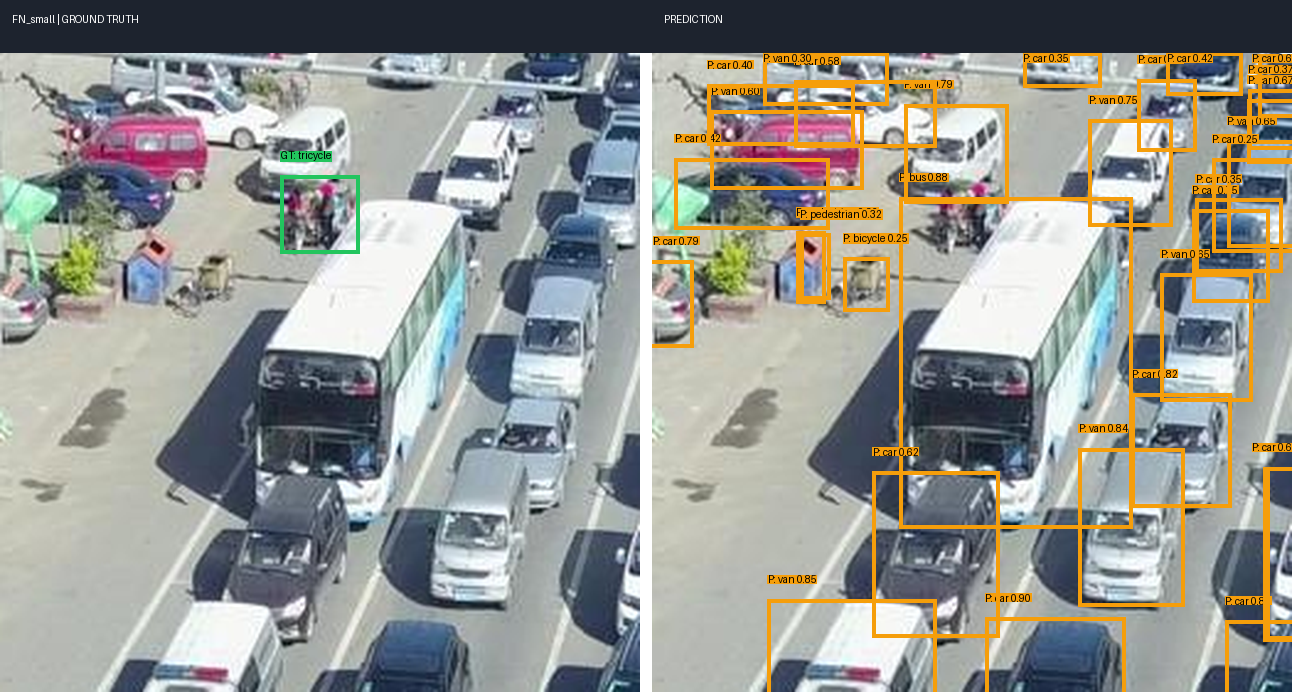


FP: det_0000289_07001_d_0000846.jpg


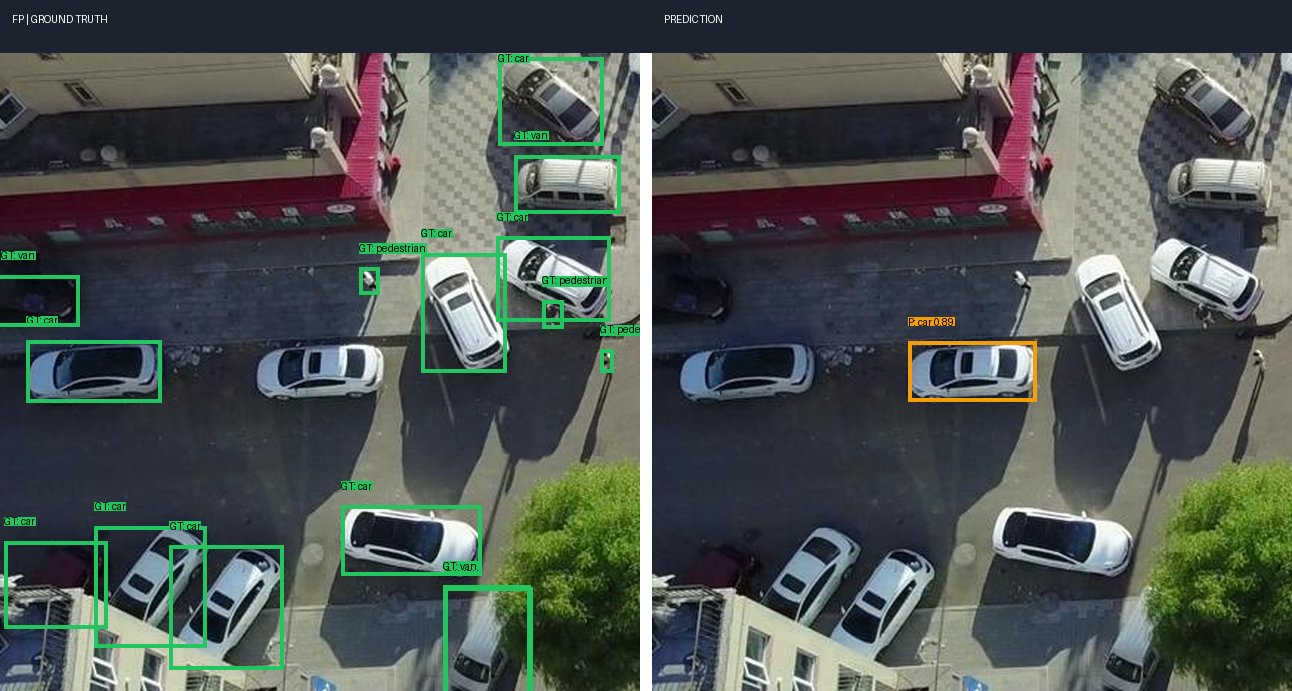


class_confusion: det_0000291_03601_d_0000886.jpg


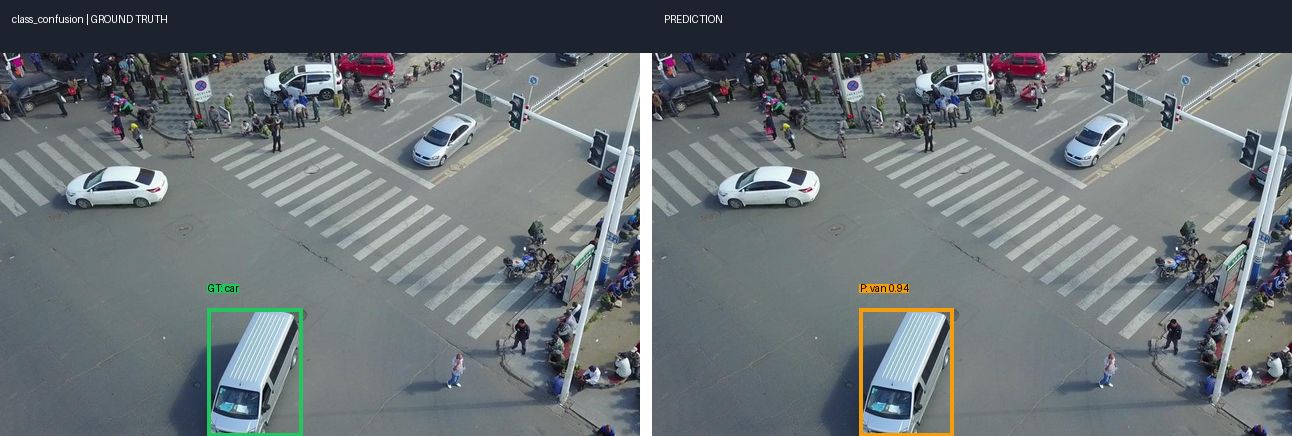

In [9]:
def font(size=17):
    try: return ImageFont.truetype('/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf',size)
    except OSError:return ImageFont.load_default()

def draw_box_on_crop(draw, box, crop, scale, color, text):
    x0,y0,x1,y1=crop
    ax,ay,bx,by=box
    X1,Y1=(ax-x0)*scale,(ay-y0)*scale
    X2,Y2=(bx-x0)*scale,(by-y0)*scale
    draw.rectangle((X1,Y1,X2,Y2),outline=color,width=4)
    tx=max(1,min(X1,600))
    ty=max(0,Y1-26)
    bbox=draw.textbbox((tx,ty),text,font=font(16))
    draw.rectangle(bbox,fill=color)
    draw.text((tx,ty),text,fill='black',font=font(16))

def export_error_crop(ex,output):
    with Image.open(ex['image']) as im:
        img=im.convert('RGB')
    W,H=img.size
    x1,y1,x2,y2=ex['box']
    cx,cy=(x1+x2)/2,(y1+y2)/2
    side=max(260,(x2-x1)*5,(y2-y1)*5)
    side=min(side,max(W,H))
    X0=max(0,int(round(cx-side/2)));Y0=max(0,int(round(cy-side/2)))
    X1=min(W,int(round(cx+side/2)));Y1=min(H,int(round(cy+side/2)))
    # Nếu ở gần biên ảnh, vẫn giữ tối thiểu nhiều vùng nền nhất có thể
    if X1-X0 < side and W>=side:
        X0=max(0,min(X0,W-int(side)));X1=min(W,X0+int(side))
    if Y1-Y0 < side and H>=side:
        Y0=max(0,min(Y0,H-int(side)));Y1=min(H,Y0+int(side))
    crop=(X0,Y0,X1,Y1)
    cropped=img.crop(crop)
    view_w=640
    scale=view_w/max(1,cropped.width)
    view_h=max(200,round(cropped.height*scale))
    base=cropped.resize((view_w,view_h),Image.Resampling.LANCZOS)
    gt_panel=base.copy(); pred_panel=base.copy()
    gd=ImageDraw.Draw(gt_panel); pd_=ImageDraw.Draw(pred_panel)
    name=lambda c:class_names.get(c,str(c))
    if ex['gt'] is not None:
        g=ex['gt']
        draw_box_on_crop(gd,g['box'],crop,scale,'#22c55e',f"GT: {name(g['cls'])}")
    else:
        # Các GT gần khu vực FP (nếu có)
        for g in ex['all_gt']:
            if xyxy_iou(g['box'],crop)>0:
                draw_box_on_crop(gd,g['box'],crop,scale,'#22c55e',f"GT: {name(g['cls'])}")
    if ex['pred'] is not None:
        p=ex['pred']
        draw_box_on_crop(pd_,p['box'],crop,scale,'#f59e0b',f"P: {name(p['cls'])} {p['conf']:.2f}")
    else:
        # FN: cho thấy tất cả prediction xung quanh (nếu có)
        for p in ex['all_pred']:
            if xyxy_iou(p['box'],crop)>0:
                draw_box_on_crop(pd_,p['box'],crop,scale,'#f59e0b',f"P: {name(p['cls'])} {p['conf']:.2f}")
    panel_height=52
    canvas=Image.new('RGB',(2*view_w+12,view_h+panel_height),(255,255,255))
    canvas.paste(gt_panel,(0,panel_height));canvas.paste(pred_panel,(view_w+12,panel_height))
    d=ImageDraw.Draw(canvas)
    d.rectangle((0,0,canvas.width,panel_height),fill=(29,35,46))
    d.text((12,13),f"{ex['kind']} | GROUND TRUTH",fill='white',font=font(18))
    d.text((view_w+24,13),'PREDICTION',fill='white',font=font(18))
    canvas.save(output,optimize=True)
    return {'crop_xyxy':list(crop),'enlarge_factor':scale,'output_image':output.name}

status={}
for index,(kind,ex) in enumerate(best_examples.items(),start=1):
    fname=f'{index:02d}_{kind}.png'
    if ex is None:
        status[kind]={'found':False,'searched_images':scanned,
                      'note':'Không có ca đáp ứng tiêu chí ở ngưỡng và số ảnh đã quét.'}
        continue
    output=ERRORS_DIR/fname
    visual=export_error_crop(ex,output)
    status[kind]={
        'found':True,'image_source':str(Path(ex['image']).name),
        'confidence_threshold':ERROR_CONF,'matching_iou_threshold':ERROR_IOU,
        'selection_iou':ex['iou'], 'target_box_xyxy':ex['box'],
        'gt_class':class_names.get(ex['gt']['cls']) if ex['gt'] else None,
        'pred_class':class_names.get(ex['pred']['cls']) if ex['pred'] else None,
        'pred_conf':ex['pred']['conf'] if ex['pred'] else None,
        **visual,
    }
    print(kind,'→',output)
(ERRORS_DIR/'examples_status.json').write_text(json.dumps(status,ensure_ascii=False,indent=2),encoding='utf-8')
print(json.dumps({k:v['found'] for k,v in status.items()},ensure_ascii=False))

# Hiển thị ngay 3 ảnh định tính nếu tìm được.
from IPython.display import display, Image as NotebookImage
for kind, entry in status.items():
    if entry['found']:
        print(f"\n{kind}: {entry['image_source']}")
        display(NotebookImage(filename=str(ERRORS_DIR / entry['output_image']), width=1050))


## 7. Lưu metadata + nhật ký train

Giữ `run_config.yaml`, `env.txt`, `results.csv`, `validation_metrics.json`, `per_class_ap.csv`, 3 crop (nếu có) và checkpoint.

In [10]:
import importlib.metadata

freeze=subprocess.run([sys.executable,'-m','pip','freeze'],capture_output=True,text=True,check=True).stdout
runtime={
    'date_utc':datetime.now(timezone.utc).isoformat(timespec='seconds'),
    'host':platform.node(), 'python':platform.python_version(),
    'torch':torch.__version__, 'ultralytics':ultralytics.__version__,
    'gpu':torch.cuda.get_device_name(DEVICE),
    'repository':REPO_URL,'repository_commit':REPO_SHA,
    'dataset':str(DATASET_ROOT), 'variant':VARIANT,
    'training_hours':duration_hours,
}
(RUN_DIR/'env.txt').write_text(json.dumps(runtime,indent=2,ensure_ascii=False)+'\n\n' + freeze, encoding='utf-8')
(RUN_DIR/'data_provenance.json').write_text(json.dumps({
    'source_kaggle_dataset':'tiendq/visdrone-mot-det-converted',
    'variant':VARIANT,'original_preprocessing':'ntrThanh/uav-tracking/data/tools/prepare.py',
    'raw_data':'VisDrone2019-MOT / VisDrone2019-DET',
    'images':n_images,
    'converted_dataset_path':str(DATASET_ROOT),
    'restore_method':'Working YOLO symlinks restored from links_manifest.json. No raw image copies.',
},ensure_ascii=False,indent=2),encoding='utf-8')

log_path=RUN_DIR/'runs_log.csv'
fields=['run_id','date','user','model','resolution','data','epochs','batch','lr','gpu',
        'duration_h','best_checkpoint','output_dir','status','notes']
record={
    'run_id':RUN_NAME,'date':datetime.now().strftime('%Y-%m-%d %H:%M'),
    'user':'kaggle','model':'yolo11m','resolution':IMGSZ,'data':VARIANT,
    'epochs':EPOCHS,'batch':BATCH,'lr':0.01,
    'gpu':torch.cuda.get_device_name(DEVICE),'duration_h':round(duration_hours,3),
    'best_checkpoint':str(BEST_PT),'output_dir':str(RUN_DIR),
    'status':'finished',
    'notes':f'actual_epochs={len(df)};best_epoch={best_epoch};val_mAP50_95={validation_summary["mAP50_95"]:.4f}',
}
with log_path.open('w',newline='',encoding='utf-8') as f:
    w=csv.DictWriter(f,fieldnames=fields);w.writeheader();w.writerow(record)
print('Output directory:',RUN_DIR)

Output directory: /kaggle/working/yolo11_runs/T1_yolo11m_640_det


## 8. Đóng gói đúng **các artifact cần thiết** (không ZIP ảnh nguồn)

Trong Kaggle Output, giữ cả thư mục run và ZIP để thuận tiện tải. ZIP **không** chứa dataset gốc, checkpoint trung gian `epoch*.pt`, cache hay ảnh train batch

In [11]:
import zipfile

# Lấy file trực tiếp của training run; tránh lưu thừa epoch checkpoints/cache.
keep_files=[
    'weights/best.pt','weights/last.pt','results.csv','results.png','args.yaml',
    'run_config.yaml','env.txt','data_provenance.json','runs_log.csv',
    'validation_metrics.json','per_class_ap.csv','training_curves_loss_map.png',
    'confusion_matrix.png','confusion_matrix_normalized.png','F1_curve.png',
    'PR_curve.png','P_curve.png','R_curve.png',
]
keep_files += [str(p.relative_to(RUN_DIR)) for p in ERRORS_DIR.glob('*') if p.is_file()]
if VALIDATION_DIR.is_dir():
    for p in VALIDATION_DIR.iterdir():
        if p.is_file() and p.suffix.lower() in ('.png','.csv','.json'):
            keep_files.append('val_best/'+p.name)
PACKAGE.unlink(missing_ok=True)
with zipfile.ZipFile(PACKAGE,'w',compression=zipfile.ZIP_STORED,allowZip64=True) as zf:
    for relative in dict.fromkeys(keep_files):
        if relative.startswith('val_best/'):
            path=VALIDATION_DIR/relative.split('/',1)[1]
        else:
            path=RUN_DIR/relative
        if path.exists():
            zf.write(path,arcname=f'{RUN_NAME}/{relative}',
                     compress_type=zipfile.ZIP_STORED if path.suffix=='.pt' else zipfile.ZIP_DEFLATED)
with zipfile.ZipFile(PACKAGE) as zf:
    assert zf.testzip() is None, 'ZIP lỗi CRC'
    arc=set(zf.namelist())
    assert f'{RUN_NAME}/weights/best.pt' in arc
    assert f'{RUN_NAME}/training_curves_loss_map.png' in arc
    print('Artifacts in ZIP:',len(arc))
    for name in sorted(arc): print('  ',name)
print('\nFINAL ZIP:',PACKAGE,'size MB:',round(PACKAGE.stat().st_size/1e6,2))
print('Note: Kaggle → Save Version → Output để lấy file ZIP và checkpoint.')

Artifacts in ZIP: 24
   T1_yolo11m_640_det/args.yaml
   T1_yolo11m_640_det/confusion_matrix.png
   T1_yolo11m_640_det/confusion_matrix_normalized.png
   T1_yolo11m_640_det/data_provenance.json
   T1_yolo11m_640_det/env.txt
   T1_yolo11m_640_det/errors/01_FN_small.png
   T1_yolo11m_640_det/errors/02_FP.png
   T1_yolo11m_640_det/errors/03_class_confusion.png
   T1_yolo11m_640_det/errors/examples_status.json
   T1_yolo11m_640_det/per_class_ap.csv
   T1_yolo11m_640_det/results.csv
   T1_yolo11m_640_det/results.png
   T1_yolo11m_640_det/run_config.yaml
   T1_yolo11m_640_det/runs_log.csv
   T1_yolo11m_640_det/training_curves_loss_map.png
   T1_yolo11m_640_det/val_best/BoxF1_curve.png
   T1_yolo11m_640_det/val_best/BoxPR_curve.png
   T1_yolo11m_640_det/val_best/BoxP_curve.png
   T1_yolo11m_640_det/val_best/BoxR_curve.png
   T1_yolo11m_640_det/val_best/confusion_matrix.png
   T1_yolo11m_640_det/val_best/confusion_matrix_normalized.png
   T1_yolo11m_640_det/validation_metrics.json
   T1_yolo11m